# PRCP-1024: Texas Salary Prediction

## 1. Project Introduction

This project analyzes salary records from Texas state government agencies to understand employee payroll patterns and develop a machine learning model for salary prediction.

## 2. Project Objectives

1. Perform comprehensive data analysis.
2. Identify salary outliers.
3. Investigate wage disparities across departments and job roles.
4. Analyze historical salary, compensation, and employee headcount changes where the available data supports these analyses.
5. Train and compare multiple predictive models.
6. Select, save, and test the best-performing model.
7. Document challenges, solutions, findings, and practical recommendations.

## 3. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## 4. Project Deliverables

A single, well-organized Jupyter Notebook containing data analysis, visualizations, model comparison, evaluation, findings, and a final project report.

In [1]:
# 1. Basic Python libraries
import os
import warnings
import pickle

# 2. Data manipulation
import pandas as pd
import numpy as np

# 3. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold
)
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 5. Machine learning models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor
)

# 6. Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 7. Outlier detection
from scipy import stats
import time
# 8. Display settings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Load the CSV file
df = pd.read_csv("salary.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (149481, 21)


,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,EMPLOY DATE,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",RUCKER,MORTON,V,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,02/18/88,75.96,29.00,9545.82,114549.84,127717,True,NaN,NaN,131407.08,NaN
1,212,OFFICE OF COURT ADMINISTRATION ...,RUCKER,MORTON,V,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,02/01/15,81.04,4.00,1404.77,16857.24,127717,True,NaN,NaN,NaN,True
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",SPECIA JR,JOHN,J,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,02/01/20,75.96,29.00,9545.82,114549.84,59115,True,NaN,NaN,131407.08,NaN
3,212,OFFICE OF COURT ADMINISTRATION ...,SPECIA JR,JOHN,J,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,09/01/18,81.04,4.00,1404.77,16857.24,59115,True,NaN,NaN,NaN,True
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,ONTIVEROS,ESTHER,,4504,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,06/29/20,0.00,40.00,3284.27,39411.24,165030,True,1.00,NaN,NaN,NaN


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['AGENCY', 'AGENCY NAME', 'LAST NAME', 'FIRST NAME', 'MI', 'CLASS CODE', 'CLASS TITLE', 'ETHNICITY', 'GENDER', 'STATUS', 'EMPLOY DATE', 'HRLY RATE', 'HRS PER WK', 'MONTHLY', 'ANNUAL', 'STATE NUMBER', 'duplicated', 'multiple_full_time_jobs', 'combined_multiple_jobs', 'summed_annual_salary', 'hide_from_search']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149481 entries, 0 to 149480
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   AGENCY                   149481 non-null  int64  
 1   AGENCY NAME              149481 non-null  object 
 2   LAST NAME                149481 non-null  object 
 3   FIRST NAME               149481 non-null  object 
 4   MI                       149481 non-null  object 
 5   CLASS CODE               149481 non-null  object 
 6   CLASS TITLE              149481 non-null  object 
 7   ETHNICITY                149481 non-null  

In [4]:
# Check missing values and duplicates
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:


multiple_full_time_jobs    149467
hide_from_search           149465
summed_annual_salary       149465
combined_multiple_jobs     149384
duplicated                 149338
HRLY RATE                       0
STATE NUMBER                    0
ANNUAL                          0
MONTHLY                         0
HRS PER WK                      0
AGENCY                          0
AGENCY NAME                     0
STATUS                          0
GENDER                          0
ETHNICITY                       0
CLASS TITLE                     0
CLASS CODE                      0
MI                              0
FIRST NAME                      0
LAST NAME                       0
EMPLOY DATE                     0
dtype: int64


Duplicate rows: 0


In [5]:
# Check the columns with many missing values
missing = df.isnull().sum()

print("Columns with missing values:")
display(missing[missing > 0].to_frame("Missing_Count"))

print("\nMissing-value percentages:")
display(
    (missing[missing > 0] / len(df) * 100)
    .round(2)
    .to_frame("Missing_Percentage")
)

Columns with missing values:


,Missing_Count
duplicated,149338
multiple_full_time_jobs,149467
combined_multiple_jobs,149384
summed_annual_salary,149465
hide_from_search,149465



Missing-value percentages:


,Missing_Percentage
duplicated,99.90
multiple_full_time_jobs,99.99
combined_multiple_jobs,99.94
summed_annual_salary,99.99
hide_from_search,99.99


In [6]:
# Inspect the affected columns
cols = [
    "multiple_full_time_jobs",
    "hide_from_search",
    "summed_annual_salary",
    "combined_multiple_jobs",
    "duplicated"
]

display(df[cols].head(10))
display(df[cols].describe(include="all").T)

,multiple_full_time_jobs,hide_from_search,summed_annual_salary,combined_multiple_jobs,duplicated
0,NaN,NaN,131407.08,NaN,True
1,NaN,True,NaN,NaN,True
2,NaN,NaN,131407.08,NaN,True
3,NaN,True,NaN,NaN,True
4,1.00,NaN,NaN,NaN,True
5,1.00,NaN,NaN,NaN,True
6,1.00,NaN,NaN,NaN,True
7,NaN,NaN,171383.40,NaN,True
8,NaN,True,NaN,NaN,True
9,1.00,NaN,NaN,NaN,True


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
multiple_full_time_jobs,14.00,NaN,NaN,NaN,1.00,0.00,1.00,1.00,1.00,1.00,1.00
hide_from_search,16,1,True,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
summed_annual_salary,16.00,NaN,NaN,NaN,74303.96,51925.94,18000.00,32962.50,48063.30,123751.77,171383.40
combined_multiple_jobs,97,1,True,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duplicated,143,1,True,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Check salary and date columns
print("Salary statistics:")
display(df[["HRLY RATE", "MONTHLY", "ANNUAL", "HRS PER WK"]].describe().T)

print("\nEmployment date sample:")
display(df["EMPLOY DATE"].head(10))

print("\nEmployment date data type:")
print(df["EMPLOY DATE"].dtype)

Salary statistics:


,count,mean,std,min,25%,50%,75%,max
HRLY RATE,149481.00,0.35,4.21,0.00,0.00,0.00,0.00,117.79
MONTHLY,149481.00,4226.18,2093.11,50.00,3019.84,3720.17,4865.81,46125.00
ANNUAL,149481.00,50714.21,25117.34,600.00,36238.08,44642.04,58389.72,553500.00
HRS PER WK,149481.00,39.71,2.32,1.00,40.00,40.00,40.00,70.00



Employment date sample:


0    02/18/88
1    02/01/15
2    02/01/20
3    09/01/18
4    06/29/20
5    04/01/20
6    06/22/20
7    03/01/20
8    03/04/20
9    09/01/19
Name: EMPLOY DATE, dtype: object


Employment date data type:
object


In [8]:
# Convert employment date
df_clean = df.copy()

df_clean["EMPLOY DATE"] = pd.to_datetime(
    df_clean["EMPLOY DATE"],
    format="%m/%d/%y",
    errors="coerce"
)

print("Employment date converted.")
print("Data type:", df_clean["EMPLOY DATE"].dtype)
print("Invalid dates:", df_clean["EMPLOY DATE"].isna().sum())

display(df_clean[["EMPLOY DATE"]].head())

Employment date converted.
Data type: datetime64[ns]
Invalid dates: 0


,EMPLOY DATE
0,1988-02-18
1,2015-02-01
2,2020-02-01
3,2018-09-01
4,2020-06-29


In [9]:
# Remove columns with excessive missing values
cols_to_drop = [
    "multiple_full_time_jobs",
    "hide_from_search",
    "summed_annual_salary",
    "combined_multiple_jobs",
    "duplicated"
]

df_clean = df_clean.drop(columns=cols_to_drop, errors="ignore")

print("Shape after removing sparse columns:", df_clean.shape)
print("\nRemaining columns:")
print(df_clean.columns.tolist())

Shape after removing sparse columns: (149481, 16)

Remaining columns:
['AGENCY', 'AGENCY NAME', 'LAST NAME', 'FIRST NAME', 'MI', 'CLASS CODE', 'CLASS TITLE', 'ETHNICITY', 'GENDER', 'STATUS', 'EMPLOY DATE', 'HRLY RATE', 'HRS PER WK', 'MONTHLY', 'ANNUAL', 'STATE NUMBER']


In [10]:
# Check and clean salary values
# Check salary columns for invalid or negative values
salary_cols = ["HRLY RATE", "MONTHLY", "ANNUAL", "HRS PER WK"]

display(df_clean[salary_cols].describe().T)

print("\nNegative values:")
display((df_clean[salary_cols] < 0).sum())

,count,mean,std,min,25%,50%,75%,max
HRLY RATE,149481.00,0.35,4.21,0.00,0.00,0.00,0.00,117.79
MONTHLY,149481.00,4226.18,2093.11,50.00,3019.84,3720.17,4865.81,46125.00
ANNUAL,149481.00,50714.21,25117.34,600.00,36238.08,44642.04,58389.72,553500.00
HRS PER WK,149481.00,39.71,2.32,1.00,40.00,40.00,40.00,70.00



Negative values:


HRLY RATE     0
MONTHLY       0
ANNUAL        0
HRS PER WK    0
dtype: int64

In [11]:
# Check salary data quality
salary_cols = ["HRLY RATE", "MONTHLY", "ANNUAL", "HRS PER WK"]

for col in salary_cols:
    print(f"\n{col}")
    print("Zero values:", (df_clean[col] == 0).sum())
    print("Negative values:", (df_clean[col] < 0).sum())
    print("Missing values:", df_clean[col].isna().sum())


HRLY RATE
Zero values: 147733
Negative values: 0
Missing values: 0

MONTHLY
Zero values: 0
Negative values: 0
Missing values: 0

ANNUAL
Zero values: 0
Negative values: 0
Missing values: 0

HRS PER WK
Zero values: 0
Negative values: 0
Missing values: 0


In [12]:
# Clean column names and verify the dataset
# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Dataset shape:", df_clean.shape)
print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nMissing values:")
display(df_clean.isnull().sum())

Dataset shape: (149481, 16)

Column names:
['agency', 'agency_name', 'last_name', 'first_name', 'mi', 'class_code', 'class_title', 'ethnicity', 'gender', 'status', 'employ_date', 'hrly_rate', 'hrs_per_wk', 'monthly', 'annual', 'state_number']

Missing values:


agency          0
agency_name     0
last_name       0
first_name      0
mi              0
class_code      0
class_title     0
ethnicity       0
gender          0
status          0
employ_date     0
hrly_rate       0
hrs_per_wk      0
monthly         0
annual          0
state_number    0
dtype: int64

In [13]:
# Exploratory Data Analysis (EDA)
print("Dataset shape:", df_clean.shape)

print("\nNumerical summary:")
display(df_clean.describe().T)

print("\nCategorical summary:")
display(df_clean.describe(include="object").T)

Dataset shape: (149481, 16)

Numerical summary:


,count,mean,min,25%,50%,75%,max,std
agency,149481.00,545.74,101.00,529.00,530.00,696.00,930.00,139.06
employ_date,149481,2014-01-12 07:50:14.486121984,1969-01-14 00:00:00,2010-12-20 00:00:00,2016-10-10 00:00:00,2018-12-03 00:00:00,2068-12-01 00:00:00,NaN
hrly_rate,149481.00,0.35,0.00,0.00,0.00,0.00,117.79,4.21
hrs_per_wk,149481.00,39.71,1.00,40.00,40.00,40.00,70.00,2.32
monthly,149481.00,4226.18,50.00,3019.84,3720.17,4865.81,46125.00,2093.11
annual,149481.00,50714.21,600.00,36238.08,44642.04,58389.72,553500.00,25117.34
state_number,149481.00,565193.02,1.00,113334.00,346373.00,1100500.00,1271604.00,478621.22



Categorical summary:


,count,unique,top,freq
agency_name,149481,113,HEALTH AND HUMAN SERVICES COMMISSION ...,36667
last_name,149481,38675,SMITH,1243
first_name,149481,23559,MICHAEL,1843
mi,149481,27,,38408
class_code,149481,1481,4504,9267
class_title,149481,1422,CORREC OFFICER IV ...,9267
ethnicity,149481,6,WHITE,67142
gender,149481,2,FEMALE,85328
status,149481,11,CRF - CLASSIFIED REGULAR FULL-TIME,142502


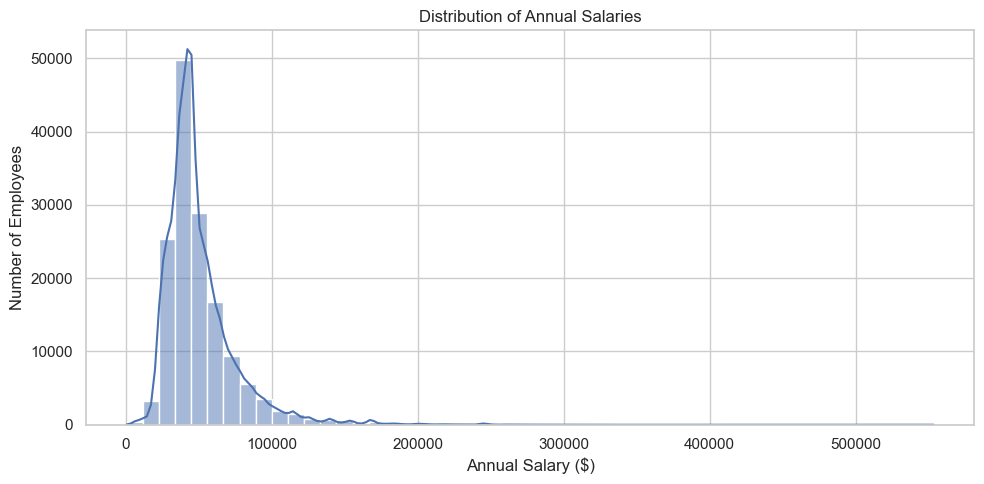

In [14]:
# Analyze annual salary distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="annual",
    bins=50,
    kde=True
)

plt.title("Distribution of Annual Salaries")
plt.xlabel("Annual Salary ($)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

### A histogram of annual salaries. A long right tail may indicate a small number of highly paid employees.`m

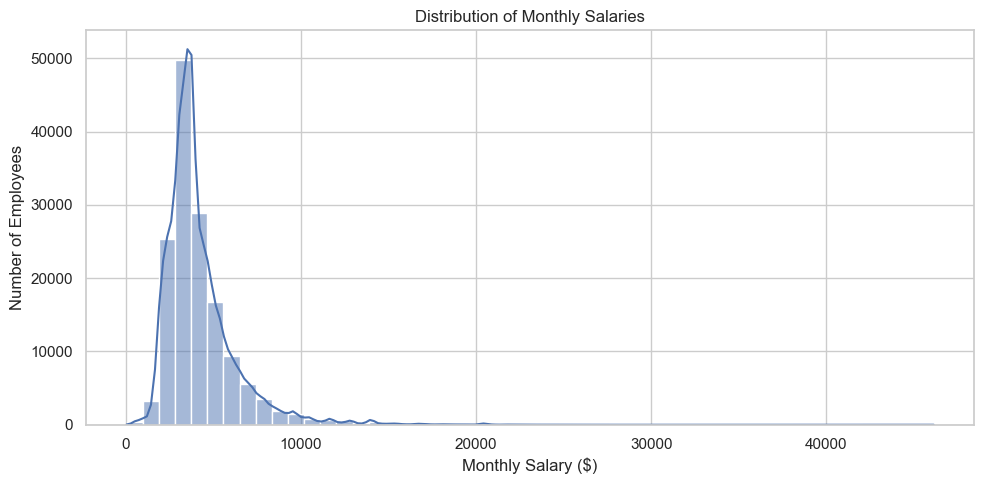

In [15]:
# Analyze monthly salary distribution
plt.figure(figsize=(10, 5))

sns.histplot(data=df_clean, x="monthly", bins=50, kde=True)

plt.title("Distribution of Monthly Salaries")
plt.xlabel("Monthly Salary ($)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

### A histogram showing the frequency of different monthly salary levels.

In [16]:
# Identify the highest-paid employees
top_salaries = df_clean.sort_values(
    by="annual",
    ascending=False
)

display(
    top_salaries[
        ["first_name", "last_name", "agency_name", "class_title", "annual"]
    ].head(10)
)

,first_name,last_name,agency_name,class_title,annual
83851,JAMES,WILLSON,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,CHIEF SCIENTIFIC OFFICER ...,553500.00
14793,JASE,AUBY,TEACHER RETIREMENT SYSTEM ...,CHIEF INVESTMENT OFFICER ...,450000.00
144232,CHARLES,TULL,EMPLOYEES RETIREMENT SYSTEM ...,DIRECTOR OF INVESTMENTS ...,450000.00
15154,ERIC,LANG,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,391999.92
136727,BARNEY,TIMMINS III,TEXAS EDUCATION AGENCY ...,PSF CHIEF INVESTMENT OFFICER ...,384375.00
15041,BRIAN,GUTHRIE,TEACHER RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR ...,355141.44
15539,DALE,WEST,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,344000.04
84769,JAMES,BASS,TEXAS DEPARTMENT OF TRANSPORTATION ...,EXECUTIVE DIRECTOR ...,343999.92
144262,PORTER,WILSON,EMPLOYEES RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR FOR ERS ...,316116.96
15349,NEIL,RANDALL,TEACHER RETIREMENT SYSTEM ...,MANAGING DIRECTOR ...,315000.00


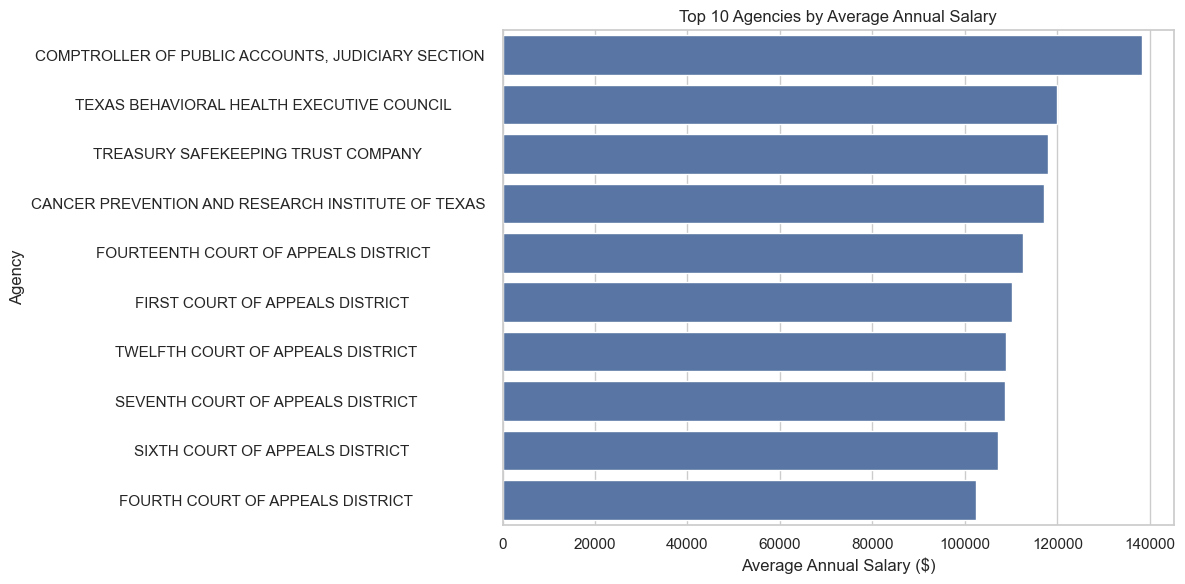

,average_annual_salary
agency_name,
"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION",138298.20
TEXAS BEHAVIORAL HEALTH EXECUTIVE COUNCIL,120000.00
TREASURY SAFEKEEPING TRUST COMPANY,117943.64
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS,117206.13
FOURTEENTH COURT OF APPEALS DISTRICT,112452.99
FIRST COURT OF APPEALS DISTRICT,110183.38
TWELFTH COURT OF APPEALS DISTRICT,108816.66
SEVENTH COURT OF APPEALS DISTRICT,108744.47
SIXTH COURT OF APPEALS DISTRICT,107096.00


In [17]:
# Compare average salaries by agency
agency_salary = (
    df_clean.groupby("agency_name")["annual"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=agency_salary.values, y=agency_salary.index)

plt.title("Top 10 Agencies by Average Annual Salary")
plt.xlabel("Average Annual Salary ($)")
plt.ylabel("Agency")
plt.tight_layout()
plt.show()

display(agency_salary.to_frame("average_annual_salary"))

,mean,median,count
class_title,,,
CHIEF SCIENTIFIC OFFICER,553500.00,553500.00,1
DIRECTOR OF INVESTMENTS,450000.00,450000.00,1
PSF CHIEF INVESTMENT OFFICER,384375.00,384375.00,1
SENIOR MANAGING DIRECTOR,319000.00,304999.98,6
EXECUTIVE DIRECTOR FOR ERS,316116.96,316116.96,1
MANAGING DIRECTOR,310999.98,310999.98,2
CHIEF INVESTMENT OFFICER,300572.00,226716.00,3
CHIEF COMPLIANCE OFFICER,295800.00,295800.00,1
EX DIRECTOR TDCJ,275500.92,275500.92,1


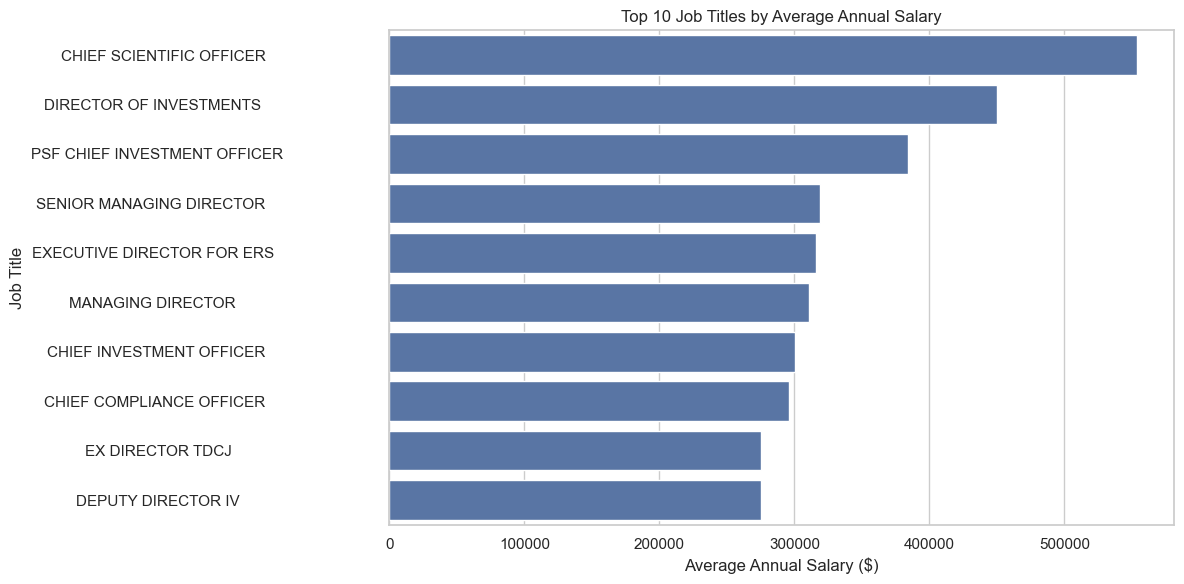

In [18]:
# Compare salaries by job title
job_salary = (
    df_clean.groupby("class_title")["annual"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
    .head(10)
)

display(job_salary)

plt.figure(figsize=(12, 6))
sns.barplot(x=job_salary["mean"], y=job_salary.index)

plt.title("Top 10 Job Titles by Average Annual Salary")
plt.xlabel("Average Annual Salary ($)")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

,count,mean,median
gender,,,
MALE,64153,54458.69,45000.00
FEMALE,85328,47898.97,43569.54


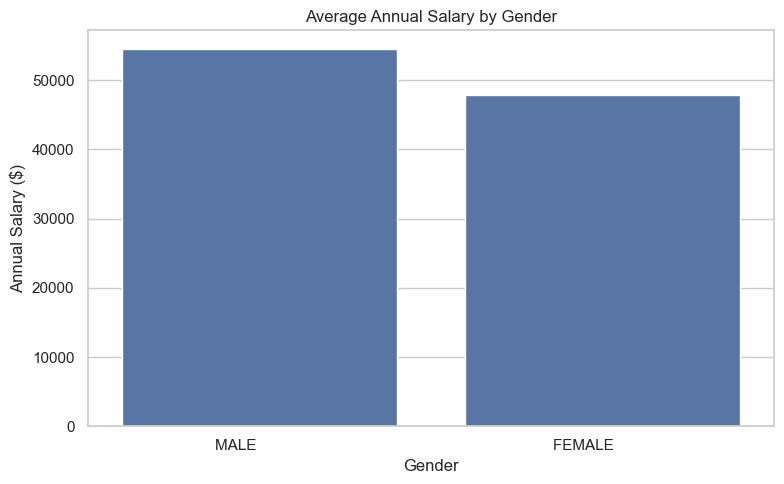

In [19]:
# Analyze salaries by gender
gender_salary = (
    df_clean.groupby("gender")["annual"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(gender_salary)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_clean, x="gender", y="annual", errorbar=None)

plt.title("Average Annual Salary by Gender")
plt.xlabel("Gender")
plt.ylabel("Annual Salary ($)")
plt.tight_layout()
plt.show()

,count,mean,median
ethnicity,,,
ASIAN,4268,63711.04,56853.54
WHITE,67142,56057.93,47677.32
AM INDIAN,712,51416.55,44642.04
HISPANIC,40585,47210.59,43300.20
OTHER,921,45544.81,38301.96
BLACK,35853,43244.73,41769.24


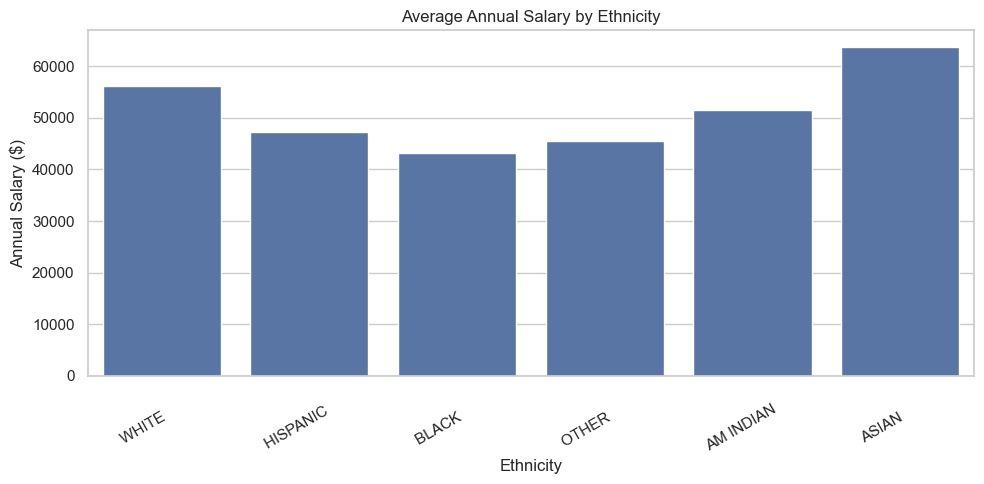

In [20]:
# Analyze salaries by ethnicity
ethnicity_salary = (
    df_clean.groupby("ethnicity")["annual"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(ethnicity_salary)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_clean, x="ethnicity", y="annual", errorbar=None)

plt.title("Average Annual Salary by Ethnicity")
plt.xlabel("Ethnicity")
plt.ylabel("Annual Salary ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [21]:
#Analyze salary outliers using the IQR method
Q1 = df_clean["annual"].quantile(0.25)
Q3 = df_clean["annual"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["annual"] < lower_bound) |
    (df_clean["annual"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of salary outliers:", len(outliers))

display(
    outliers.sort_values("annual", ascending=False)[
        ["first_name", "last_name", "agency_name", "class_title", "annual"]
    ].head(20)
)

Lower bound: 3010.6200000000026
Upper bound: 91617.18
Number of salary outliers: 9031


,first_name,last_name,agency_name,class_title,annual
83851,JAMES,WILLSON,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,CHIEF SCIENTIFIC OFFICER ...,553500.00
14793,JASE,AUBY,TEACHER RETIREMENT SYSTEM ...,CHIEF INVESTMENT OFFICER ...,450000.00
144232,CHARLES,TULL,EMPLOYEES RETIREMENT SYSTEM ...,DIRECTOR OF INVESTMENTS ...,450000.00
15154,ERIC,LANG,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,391999.92
136727,BARNEY,TIMMINS III,TEXAS EDUCATION AGENCY ...,PSF CHIEF INVESTMENT OFFICER ...,384375.00
15041,BRIAN,GUTHRIE,TEACHER RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR ...,355141.44
15539,DALE,WEST,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,344000.04
84769,JAMES,BASS,TEXAS DEPARTMENT OF TRANSPORTATION ...,EXECUTIVE DIRECTOR ...,343999.92
144262,PORTER,WILSON,EMPLOYEES RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR FOR ERS ...,316116.96
15349,NEIL,RANDALL,TEACHER RETIREMENT SYSTEM ...,MANAGING DIRECTOR ...,315000.00


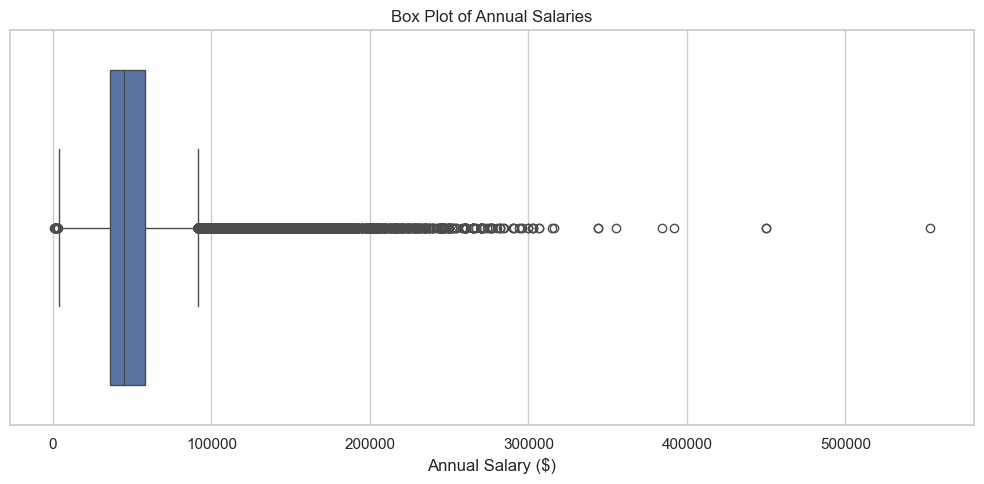

In [22]:
# Visualize salary outliers
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_clean["annual"])

plt.title("Box Plot of Annual Salaries")
plt.xlabel("Annual Salary ($)")
plt.tight_layout()
plt.show()

In [23]:
# Analyze wage disparities by agency
agency_gap = (
    df_clean.groupby("agency_name")["annual"]
    .agg(["min", "median", "max", "count"])
)

agency_gap["salary_gap"] = agency_gap["max"] - agency_gap["min"]

agency_gap = agency_gap[
    agency_gap["count"] >= 10
].sort_values("salary_gap", ascending=False)

display(agency_gap.head(10))

,min,median,max,count,salary_gap
agency_name,,,,,
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS,60000.00,74476.68,553500.00,33,493500.00
TEACHER RETIREMENT SYSTEM,13338.00,79504.08,450000.00,816,436662.00
EMPLOYEES RETIREMENT SYSTEM,31200.00,75978.96,450000.00,368,418800.00
TEXAS EDUCATION AGENCY,31742.76,80004.00,384375.00,967,352632.24
TEXAS DEPARTMENT OF TRANSPORTATION,9828.00,50004.00,343999.92,13099,334171.92
HOUSE OF REPRESENTATIVES,600.00,36000.00,279996.00,781,279396.00
SENATE,1039.92,49193.58,276500.04,504,275460.12
HEALTH AND HUMAN SERVICES COMMISSION,4710.72,33103.08,270000.00,36667,265289.28
TEXAS DEPARTMENT OF CRIMINAL JUSTICE,10866.00,41769.24,275500.92,35926,264634.92


,employee_count
agency_name,
HEALTH AND HUMAN SERVICES COMMISSION,36667
TEXAS DEPARTMENT OF CRIMINAL JUSTICE,35926
TEXAS DEPARTMENT OF TRANSPORTATION,13099
DEPARTMENT OF FAMILY AND PROTECTIVE SERVICES,12588
DEPARTMENT OF PUBLIC SAFETY,10097
TEXAS WORKFORCE COMMISSION,4653
OFFICE OF THE ATTORNEY GENERAL,4141
DEPARTMENT OF STATE HEALTH SERVICES,3129
PARKS AND WILDLIFE DEPARTMENT,3060


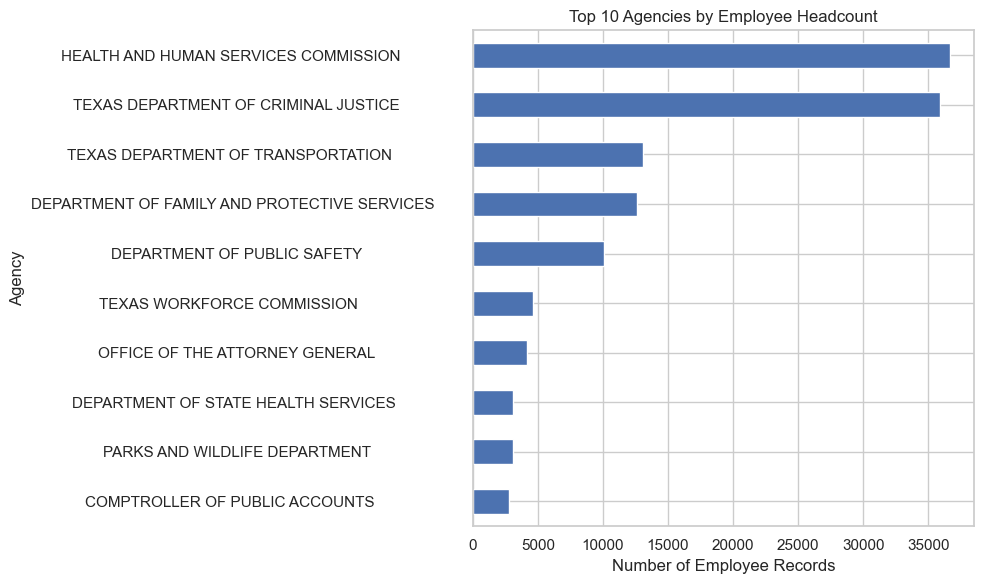

In [24]:
# Analyze employee headcount by agency
headcount = (
    df_clean.groupby("agency_name")
    .size()
    .sort_values(ascending=False)
)

display(headcount.head(10).to_frame("employee_count"))

headcount.head(10).sort_values().plot(
    kind="barh", figsize=(10, 6)
)

plt.title("Top 10 Agencies by Employee Headcount")
plt.xlabel("Number of Employee Records")
plt.ylabel("Agency")
plt.tight_layout()
plt.show()

In [25]:
# Analyze employment trends by year
df_clean["employment_year"] = df_clean["employ_date"].dt.year

yearly_analysis = (
    df_clean.groupby("employment_year")
    .agg(
        employee_count=("annual", "count"),
        average_salary=("annual", "mean"),
        median_salary=("annual", "median")
    )
    .sort_index()
)

display(yearly_analysis.tail(20))

,employee_count,average_salary,median_salary
employment_year,,,
2002,1682,64248.76,56657.34
2003,1468,64446.03,55936.20
2004,3548,56794.59,50492.46
2005,2665,60324.80,52890.00
2006,2878,56662.62,49218.00
2007,3356,58863.26,51804.24
2008,3907,54750.83,46894.68
2009,3513,55865.00,46286.76
2010,2963,56290.55,49218.00


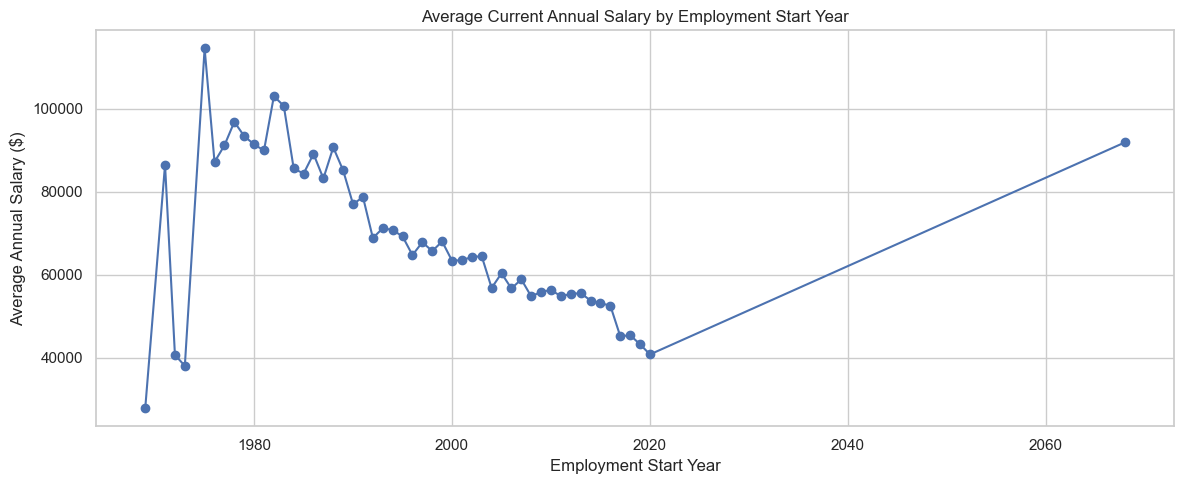

In [26]:
# Visualize salary patterns by employment year
yearly_salary = (
    df_clean.groupby("employment_year")["annual"]
    .mean()
    .dropna()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(yearly_salary.index, yearly_salary.values, marker="o")

plt.title("Average Current Annual Salary by Employment Start Year")
plt.xlabel("Employment Start Year")
plt.ylabel("Average Annual Salary ($)")
plt.tight_layout()
plt.show()

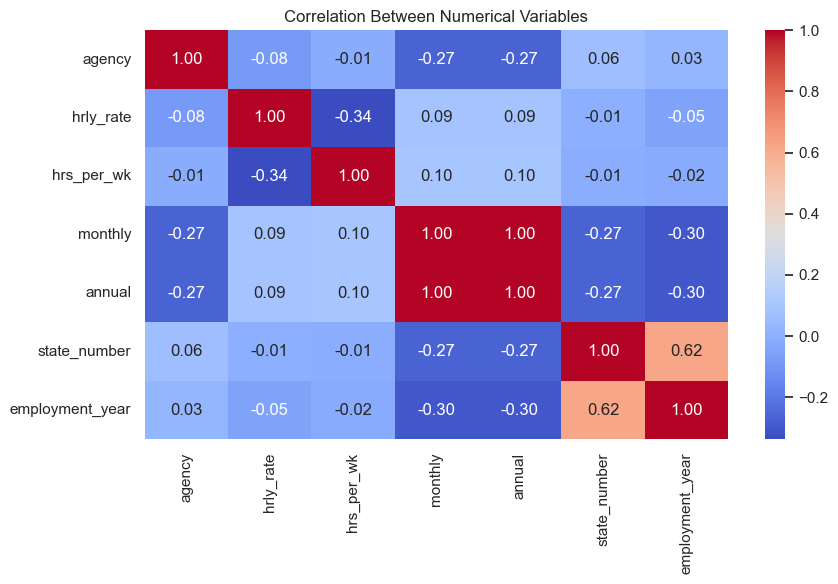

In [27]:
# Create a correlation heatmap
numeric_cols = df_clean.select_dtypes(include="number")

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

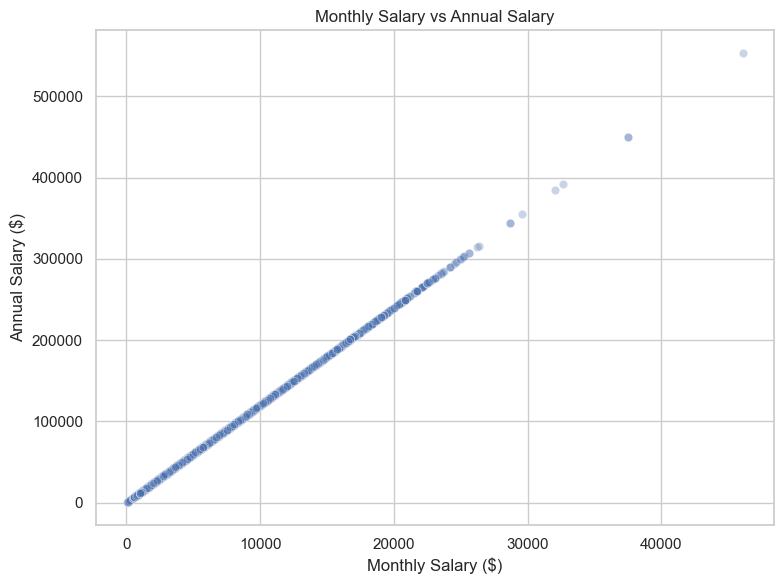

In [28]:
# Compare annual and monthly salary
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_clean,
    x="monthly",
    y="annual",
    alpha=0.3
)

plt.title("Monthly Salary vs Annual Salary")
plt.xlabel("Monthly Salary ($)")
plt.ylabel("Annual Salary ($)")
plt.tight_layout()
plt.show()

,count,mean,median
status,,,
ERF - EXEMPT REGULAR FULL-TIME,923,155908.36,153999.96
URF - UNCLASSIFIED REGULAR FULL-TIME,2363,68286.68,62394.72
URP - UNCLASSIFIED REGULAR PART-TIME,950,67191.24,60135.60
ERP - EXEMPT REGULAR PART-TIME,1,51383.40,51383.40
CRF - CLASSIFIED REGULAR FULL-TIME,142502,50076.06,44642.04
UTF - UNCLASSIFIED TEMPORARY FULL-TIME,12,38233.83,31488.00
CTF - CLASSIFIED TEMPORARY FULL-TIME,1096,33438.02,31330.50
CRP - CLASSIFIED REGULAR PART-TIME,1531,23939.81,19705.68
CTP - CLASSIFIED TEMPORARY FULL-TIME,1,23919.84,23919.84


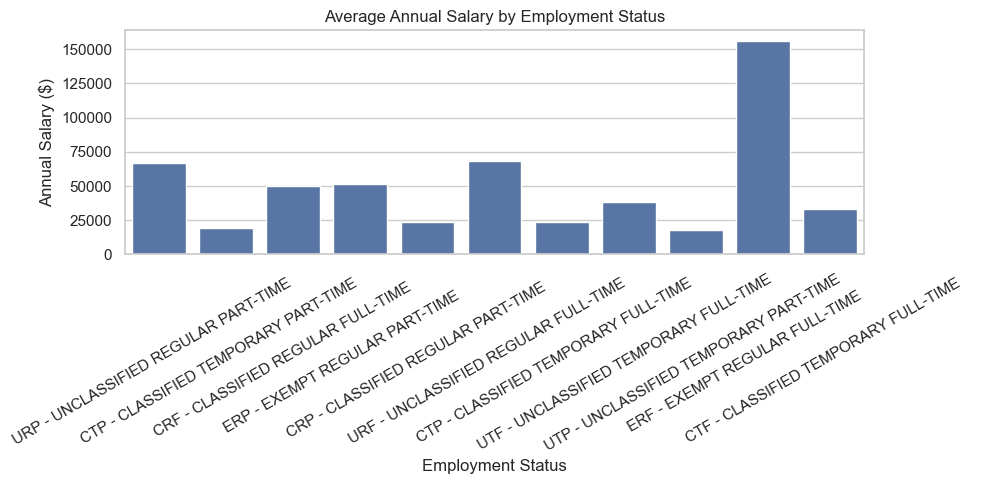

In [29]:
# Compare salary by employment status
status_salary = (
    df_clean.groupby("status")["annual"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(status_salary)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_clean,
    x="status",
    y="annual",
    errorbar=None
)

plt.title("Average Annual Salary by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Annual Salary ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Data Analysis Report

### 1. Dataset Overview
The dataset contains 149,481 initially loaded employee records and 21 columns. Five columns with extensive missing values were removed from the analytical copy for the initial analysis.

### 2. Salary Distribution
The annual and monthly salary distributions were visualized using histograms. The box plot and IQR method were used to identify unusually high or low annual salary records.

### 3. Agency and Job-Title Analysis
Agency-level and job-title-level salary summaries were calculated to identify differences in average and median compensation.

### 4. Demographic Analysis
Salary patterns were compared across recorded gender and ethnicity categories. These descriptive comparisons do not establish the cause of any observed differences.

### 5. Outlier Analysis
The IQR method identified [insert count] potential annual salary outliers. These observations require contextual review and were not automatically removed.

### 6. Workforce Analysis
Agency headcounts and employment start-year cohorts were examined. Employment start dates are not equivalent to historical payroll snapshots, so they cannot independently establish year-over-year salary changes.

### 7. Limitations
The dataset's available fields must be checked for a manager indicator and historical compensation records. If those fields are absent, manager-versus-employee comparisons and true historical compensation changes cannot be conclusively measured from this dataset alone.

In [30]:
# Check salary relationships and dataset quality
# Check relationships between salary columns
print("Annual and Monthly Salary Correlation:")
print(df_clean[["annual", "monthly"]].corr())

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum().sort_values(ascending=False).head(10))

print("\nSalary summary by employment status:")
display(
    df_clean.groupby("status")["annual"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Annual and Monthly Salary Correlation:
         annual  monthly
annual     1.00     1.00
monthly    1.00     1.00

Missing values after cleaning:


agency          0
status          0
state_number    0
annual          0
monthly         0
hrs_per_wk      0
hrly_rate       0
employ_date     0
gender          0
agency_name     0
dtype: int64


Salary summary by employment status:


,count,mean,median,min,max
status,,,,,
CRF - CLASSIFIED REGULAR FULL-TIME,142502,50076.06,44642.04,18892.92,300000.00
CRP - CLASSIFIED REGULAR PART-TIME,1531,23939.81,19705.68,4710.72,243000.00
CTF - CLASSIFIED TEMPORARY FULL-TIME,1096,33438.02,31330.50,21944.04,96720.00
CTP - CLASSIFIED TEMPORARY FULL-TIME,1,23919.84,23919.84,23919.84,23919.84
CTP - CLASSIFIED TEMPORARY PART-TIME,81,19351.09,16707.60,10971.96,92335.32
ERF - EXEMPT REGULAR FULL-TIME,923,155908.36,153999.96,8699.16,553500.00
ERP - EXEMPT REGULAR PART-TIME,1,51383.40,51383.40,51383.40,51383.40
URF - UNCLASSIFIED REGULAR FULL-TIME,2363,68286.68,62394.72,2400.00,450000.00
URP - UNCLASSIFIED REGULAR PART-TIME,950,67191.24,60135.60,600.00,114549.84


In [31]:
# Generate key findings automatically
# Final Exploratory Data Analysis Findings

print("TEXAS SALARY DATASET — EDA FINDINGS")
print("=" * 50)

print(f"Total employees/records: {len(df_clean):,}")
print(f"Total columns: {df_clean.shape[1]}")
print(f"Unique agencies: {df_clean['agency_name'].nunique():,}")
print(f"Unique job titles: {df_clean['class_title'].nunique():,}")

print("\nANNUAL SALARY")
print("-" * 30)
print(f"Mean: ${df_clean['annual'].mean():,.2f}")
print(f"Median: ${df_clean['annual'].median():,.2f}")
print(f"Minimum: ${df_clean['annual'].min():,.2f}")
print(f"Maximum: ${df_clean['annual'].max():,.2f}")

print("\nHIGHEST-AVERAGE-SALARY AGENCIES")
display(
    df_clean.groupby("agency_name")["annual"]
    .agg(["mean", "median", "count"])
    .query("count >= 10")
    .sort_values("mean", ascending=False)
    .head(10)
    .round(2)
)

print("\nMOST COMMON JOB TITLES")
display(df_clean["class_title"].value_counts().head(10))

print("\nSALARY OUTLIERS")
print(f"IQR-based outlier records: {len(outliers):,}")

print("\nMISSING VALUES")
print(f"Total missing cells remaining: {df_clean.isnull().sum().sum():,}")

TEXAS SALARY DATASET — EDA FINDINGS
Total employees/records: 149,481
Total columns: 17
Unique agencies: 113
Unique job titles: 1,422

ANNUAL SALARY
------------------------------
Mean: $50,714.21
Median: $44,642.04
Minimum: $600.00
Maximum: $553,500.00

HIGHEST-AVERAGE-SALARY AGENCIES


,mean,median,count
agency_name,,,
"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION",138298.20,139999.92,1033
TREASURY SAFEKEEPING TRUST COMPANY,117943.64,102120.00,71
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS,117206.13,74476.68,33
FOURTEENTH COURT OF APPEALS DISTRICT,112452.99,107686.44,40
FIRST COURT OF APPEALS DISTRICT,110183.38,107686.44,37
TWELFTH COURT OF APPEALS DISTRICT,108816.66,102750.00,15
SEVENTH COURT OF APPEALS DISTRICT,108744.47,101000.04,18
SIXTH COURT OF APPEALS DISTRICT,107096.00,105600.00,15
FOURTH COURT OF APPEALS DISTRICT,102458.39,97527.48,33



MOST COMMON JOB TITLES


class_title
CORREC  OFFICER IV                                    9267
CORREC  OFFICER V                                     7895
CORREC OFFCR III                                      4718
TEXAS WORKS ADVISOR II                                3646
DIRECT SUPPORT PROFESSIONAL I                         3307
TROOPER                                               2251
CHILD PROTECTIVE SVCS SPEC IV                         1854
CHILD PROTECTIVE SVCS SPEC I                          1773
ADMINISTRATIVE ASST III                               1771
SGT OF CORREC OFFCRS                                  1743
Name: count, dtype: int64


SALARY OUTLIERS
IQR-based outlier records: 9,031

MISSING VALUES
Total missing cells remaining: 0


# Exploratory Data Analysis Report

## 1. Dataset Overview
The dataset contains Texas state government payroll records.
The analysis examined employee salaries, agencies, job titles,
employment details, and demographic categories.

## 2. Salary Distribution
Annual salary statistics, including the mean, median, minimum,
and maximum, were calculated. Histograms and boxplots were
used to study the salary distribution and identify extreme values.

## 3. Agency and Job Title Analysis
Agencies and job titles were compared using salary summaries.
Groups with fewer than 10 records were excluded from the
highest-average-agency comparison to reduce unreliable rankings.

## 4. Demographic and Employment Analysis
Salary patterns were explored by gender, ethnicity, and
employment status. These are descriptive comparisons and do not
establish the reasons behind salary differences.

## 5. Outlier Analysis
The Interquartile Range (IQR) method identified unusually low
or high annual salaries. These observations require investigation
and should not automatically be treated as errors.

## 6. Limitations
Employment date represents the employment date, not necessarily
the date a salary was recorded. Therefore, it cannot by itself
establish year-over-year salary changes. Direct manager-versus-
employee comparisons and total-compensation analysis may also be
limited by the available fields.

## 7. Conclusion
The EDA provides a foundation for salary prediction and highlights
salary variation across agencies, job titles, and employee groups.

In [32]:
# Prepare data for machine learning


# Select target and candidate features
target = "annual"

features = [
    "agency",
    "agency_name",
    "class_title",
    "ethnicity",
    "gender",
    "status",
    "hrs_per_wk",
    "hrly_rate",
    "monthly"
]

# Keep only columns that exist
features = [col for col in features if col in df_clean.columns]
# Create model dataset
model_data = df_clean[features + [target]].copy()

# Remove missing or invalid target values
model_data = model_data.dropna(subset=[target])
model_data = model_data[model_data[target] > 0].copy()

print("Selected features:", features)
print("Model dataset shape:", model_data.shape)
print("Missing target values:", model_data[target].isnull().sum())

display(model_data.head())


Selected features: ['agency', 'agency_name', 'class_title', 'ethnicity', 'gender', 'status', 'hrs_per_wk', 'hrly_rate', 'monthly']
Model dataset shape: (149481, 10)
Missing target values: 0


,agency,agency_name,class_title,ethnicity,gender,status,hrs_per_wk,hrly_rate,monthly,annual
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...","JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,29.00,75.96,9545.82,114549.84
1,212,OFFICE OF COURT ADMINISTRATION ...,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,4.00,81.04,1404.77,16857.24
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...","JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,29.00,75.96,9545.82,114549.84
3,212,OFFICE OF COURT ADMINISTRATION ...,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,4.00,81.04,1404.77,16857.24
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,40.00,0.00,3284.27,39411.24


In [33]:
# Separate features and target
X = model_data[features].copy()
y = model_data[target].copy()

In [34]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['agency', 'hrs_per_wk', 'hrly_rate', 'monthly']
Categorical features: ['agency_name', 'class_title', 'ethnicity', 'gender', 'status']


In [35]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)
print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)



Training samples: 119584
Testing samples: 29897
Training target shape: (119584,)
Testing target shape: (29897,)


In [36]:
# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['agency', 'hrs_per_wk', 'hrly_rate', 'monthly']
Categorical features: ['agency_name', 'class_title', 'ethnicity', 'gender', 'status']


In [37]:
# Preprocessing pipeline for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing pipeline for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


In [38]:
# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("\nPreprocessing pipeline created successfully!")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))



Preprocessing pipeline created successfully!
Numerical features: 4
Categorical features: 5


### Train multiple ML models

In [39]:
# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Decision Tree": DecisionTreeRegressor(max_depth=15, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=15, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100, max_depth=15, random_state=42, n_jobs=-1
    )
}

print("Models:", list(models.keys()))

Models: ['Linear Regression', 'Ridge Regression', 'Decision Tree', 'Random Forest', 'Extra Trees']


In [40]:
#Initialize results
results = []
trained_models = {}

print("Ready to train models.")

Ready to train models.


In [41]:
# Train and evaluate all models
for name, algorithm in models.items():
    print("Training:", name)
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions),
        "Time (seconds)": round(time.time() - start, 2)
    })

    trained_models[name] = pipeline

print("All models trained!")

Training: Linear Regression
Training: Ridge Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
All models trained!


In [42]:
# Compare model performance
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE").reset_index(drop=True)

display(results_df.round(3))

,Model,MAE,RMSE,R2 Score,Time (seconds)
0,Linear Regression,0.10,0.23,1.00,4.43
1,Random Forest,9.51,996.70,1.00,626.19
2,Decision Tree,11.17,1056.76,1.00,50.21
3,Ridge Regression,20.97,30.97,1.00,2.27
4,Extra Trees,85.31,1241.86,1.00,171.01


In [43]:
# Select the best model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on MAE:", best_model_name)
print("MAE:", round(results_df.iloc[0]["MAE"], 2))
print("RMSE:", round(results_df.iloc[0]["RMSE"], 2))
print("R2 Score:", round(results_df.iloc[0]["R2 Score"], 4))

Best model based on MAE: Linear Regression
MAE: 0.1
RMSE: 0.23
R2 Score: 1.0


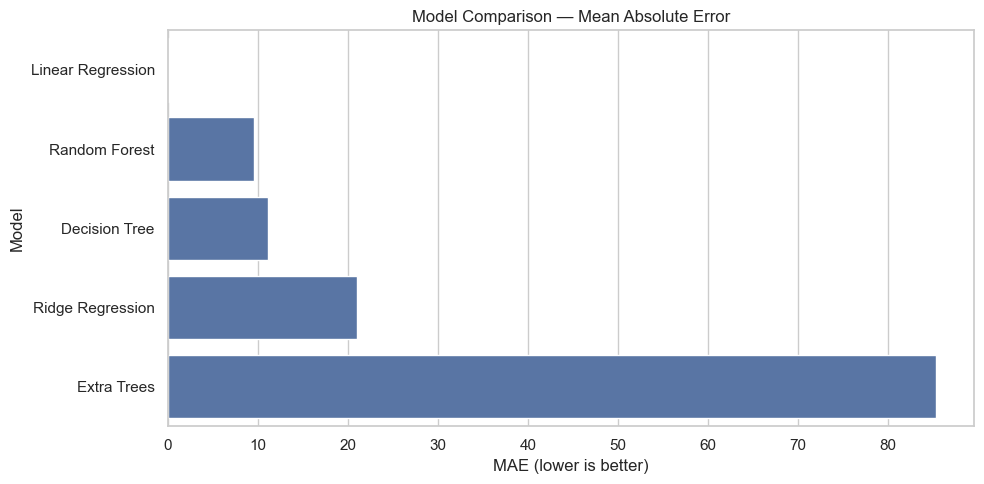

In [44]:
# Visualize model comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="MAE", y="Model")
plt.title("Model Comparison — Mean Absolute Error")
plt.xlabel("MAE (lower is better)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

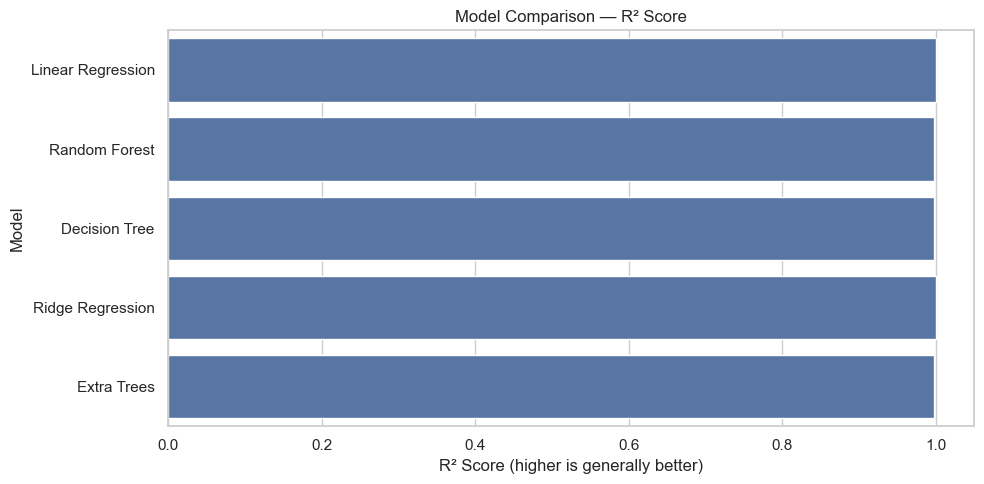

In [45]:
#Plot R² scores
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="R2 Score", y="Model")
plt.title("Model Comparison — R² Score")
plt.xlabel("R² Score (higher is generally better)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

In [46]:
# Generate predictions using the best model

y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("Actual salaries:", y_test.head().tolist())
print("Predicted salaries:", y_pred[:5].round(2).tolist())

Best Model: Linear Regression
Actual salaries: [22275.24, 36310.92, 79132.56, 41512.44, 81999.96]
Predicted salaries: [22275.27, 36310.96, 79132.75, 41512.46, 81999.92]


In [47]:
# Analyze Prediction Errors.
error_df = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": y_pred
})

error_df["Error"] = error_df["Actual Salary"] - error_df["Predicted Salary"]
error_df["Absolute Error"] = error_df["Error"].abs()

display(error_df.head(10).round(2))

print("Mean absolute error:", round(error_df["Absolute Error"].mean(), 2))
print("Largest absolute error:", round(error_df["Absolute Error"].max(), 2))


,Actual Salary,Predicted Salary,Error,Absolute Error
133445,22275.24,22275.27,-0.03,0.03
23389,36310.92,36310.96,-0.04,0.04
85047,79132.56,79132.75,-0.19,0.19
27688,41512.44,41512.46,-0.02,0.02
99000,81999.96,81999.92,0.04,0.04
67601,32377.08,32377.09,-0.01,0.01
33068,71668.44,71668.56,-0.12,0.12
76663,42873.60,42873.75,-0.15,0.15
56691,39037.20,39037.29,-0.09,0.09
111385,44642.04,44642.06,-0.02,0.02


Mean absolute error: 0.1
Largest absolute error: 11.88


In [48]:
# Evaluate model performance

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Best Model:", best_model_name)
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")

Best Model: Linear Regression
MAE: $0.10
RMSE: $0.23
R2 Score: 1.0000


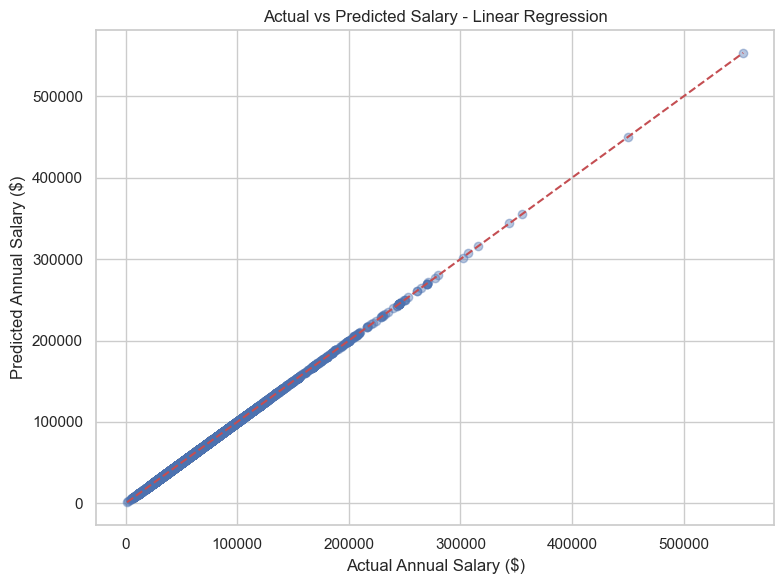

In [49]:
# Plot actual vs. predicted salaries

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Annual Salary ($)")
plt.ylabel("Predicted Annual Salary ($)")
plt.title(f"Actual vs Predicted Salary - {best_model_name}")
plt.tight_layout()
plt.show()

In [50]:
# Analyze prediction errors
error_df = pd.DataFrame({
    "Actual Salary": y_test.to_numpy(),
    "Predicted Salary": y_pred
})

error_df["Error"] = (
    error_df["Actual Salary"] - error_df["Predicted Salary"]
)
error_df["Absolute Error"] = error_df["Error"].abs()

display(error_df.head(10).round(2))

print("Mean absolute error:", round(error_df["Absolute Error"].mean(), 2))
print("Largest absolute error:", round(error_df["Absolute Error"].max(), 2))

,Actual Salary,Predicted Salary,Error,Absolute Error
0,22275.24,22275.27,-0.03,0.03
1,36310.92,36310.96,-0.04,0.04
2,79132.56,79132.75,-0.19,0.19
3,41512.44,41512.46,-0.02,0.02
4,81999.96,81999.92,0.04,0.04
5,32377.08,32377.09,-0.01,0.01
6,71668.44,71668.56,-0.12,0.12
7,42873.60,42873.75,-0.15,0.15
8,39037.20,39037.29,-0.09,0.09
9,44642.04,44642.06,-0.02,0.02


Mean absolute error: 0.1
Largest absolute error: 11.88


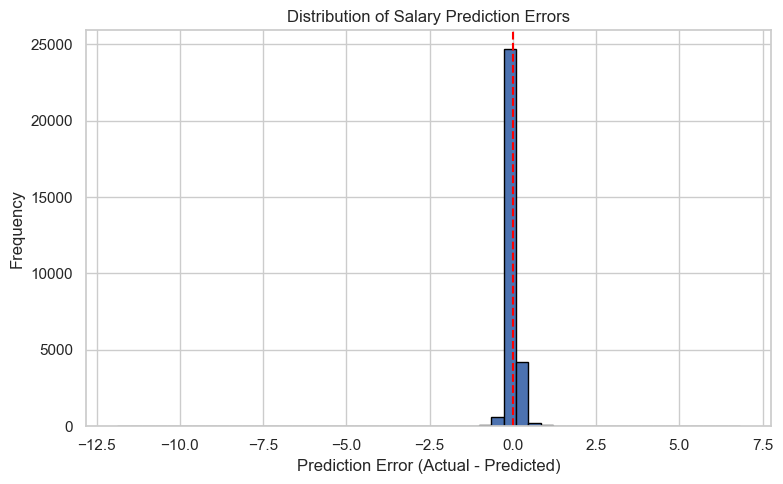

In [51]:
#Plot the distribution of prediction errors
plt.figure(figsize=(8, 5))
plt.hist(error_df["Error"], bins=50, edgecolor="black")

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Salary Prediction Errors")
plt.tight_layout()
plt.show()

In [53]:
# Review the best model's results
print("FINAL MODEL EVALUATION")
print("=" * 35)
print("Selected Model:", best_model_name)
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")

FINAL MODEL EVALUATION
Selected Model: Linear Regression
MAE: $0.10
RMSE: $0.23
R2 Score: 1.0000


# Final Model Evaluation

The selected regression model was evaluated using the test dataset.

- **MAE:** Measures the average absolute difference between
  actual and predicted salaries.
- **RMSE:** Measures prediction error while penalizing larger errors.
- **R² Score:** Measures how much variation in annual salary
  the model explains.

The actual-versus-predicted plot was used to visually inspect
prediction accuracy. Prediction errors were also analyzed to
identify cases where salary estimates differed substantially
from actual salaries.

The selected model was chosen based on its comparative
performance. Its results should be interpreted with caution,
as salary predictions depend on the features available in
the dataset and do not establish the causes of salary differences.

In [54]:
# Save the best model
import pickle

with open("texas_salary_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Best model saved successfully!")
print("Model:", best_model_name)
print("File: texas_salary_model.pkl")


Best model saved successfully!
Model: Linear Regression
File: texas_salary_model.pkl


In [55]:
# Load and verify the saved model
import pickle

with open("texas_salary_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Saved model loaded successfully!")
print("Model type:", type(loaded_model).__name__)


Saved model loaded successfully!
Model type: Pipeline


In [56]:
# Predict a sample salary

# Select one test record
sample = X_test.iloc[[0]]

# Predict annual salary
sample_prediction = loaded_model.predict(sample)[0]
actual_salary = y_test.iloc[0]

print("Predicted Annual Salary: $", round(sample_prediction, 2))
print("Actual Annual Salary: $", round(actual_salary, 2))
print("Absolute Error: $", round(abs(actual_salary - sample_prediction), 2))

Predicted Annual Salary: $ 22275.27
Actual Annual Salary: $ 22275.24
Absolute Error: $ 0.03


In [57]:
# Test a custom salary prediction

# Create a sample input using an existing test record
sample_input = X_test.iloc[[0]].copy()

# Predict annual salary
custom_prediction = loaded_model.predict(sample_input)[0]

print("Sample Input:")
display(sample_input)

print(f"Predicted Annual Salary: ${custom_prediction:,.2f}")

Sample Input:


,agency,agency_name,class_title,ethnicity,gender,status,hrs_per_wk,hrly_rate,monthly
133445,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,CLERK I ...,HISPANIC,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,40.00,0.00,1856.27


Predicted Annual Salary: $22,275.27


In [58]:
# Test another salary prediction

# Select another test record
sample_input = X_test.iloc[[10]].copy()

# Predict annual salary
prediction = loaded_model.predict(sample_input)[0]

print("Input Details:")
display(sample_input)

print(f"Predicted Annual Salary: ${prediction:,.2f}")

Input Details:


,agency,agency_name,class_title,ethnicity,gender,status,hrs_per_wk,hrly_rate,monthly
144930,456,BOARD OF PLUMBING EXAMINERS ...,PROGRAM SPECIALIST I ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,40.00,0.00,4331.65


Predicted Annual Salary: $51,979.74


In [59]:
# Verify the saved model file.
import os

file_path = "texas_salary_model.pkl"

print("Model file exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

Model file exists: True
File size: 91.22 KB


In [60]:
# Save model comparison results

results_df.to_csv("texas_salary_model_comparison.csv", index=False)

print("Model comparison saved successfully!")
print("File: texas_salary_model_comparison.csv")


Model comparison saved successfully!
File: texas_salary_model_comparison.csv



# Model Saving and Testing

The selected machine learning model was saved as
`texas_salary_model.pkl` using Python's pickle module.

The saved model was loaded and tested using records from
the test dataset. Predicted salaries were compared with
actual salaries to check the model's prediction output.

The model comparison results were exported to
`texas_salary_model_comparison.csv` for future reference.

The saved pipeline contains the preprocessing steps and
trained model, allowing consistent predictions when new
data is provided with the same input columns.


In [61]:
#Final project findings

print("=" * 55)
print("TEXAS SALARY PREDICTION — FINAL FINDINGS")
print("=" * 55)

print("Dataset records used:", len(model_data))
print("Number of input features:", len(features))
print("Selected model:", best_model_name)
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

print("\nMODEL COMPARISON")
display(results_df.round(3))

print("\nTOP 5 AGENCIES BY AVERAGE ANNUAL SALARY")
agency_summary = (
    df_clean.groupby("agency_name")["annual"]
    .agg(["mean", "count"])
    .query("count >= 10")
    .sort_values("mean", ascending=False)
    .head(5)
    .round(2)
)
display(agency_summary)


TEXAS SALARY PREDICTION — FINAL FINDINGS
Dataset records used: 149481
Number of input features: 9
Selected model: Linear Regression
Mean Absolute Error (MAE): $0.10
Root Mean Squared Error (RMSE): $0.23
R² Score: 1.0000

MODEL COMPARISON


,Model,MAE,RMSE,R2 Score,Time (seconds)
0,Linear Regression,0.10,0.23,1.00,4.43
1,Random Forest,9.51,996.70,1.00,626.19
2,Decision Tree,11.17,1056.76,1.00,50.21
3,Ridge Regression,20.97,30.97,1.00,2.27
4,Extra Trees,85.31,1241.86,1.00,171.01



TOP 5 AGENCIES BY AVERAGE ANNUAL SALARY


,mean,count
agency_name,,
"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION",138298.20,1033
TREASURY SAFEKEEPING TRUST COMPANY,117943.64,71
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS,117206.13,33
FOURTEENTH COURT OF APPEALS DISTRICT,112452.99,40
FIRST COURT OF APPEALS DISTRICT,110183.38,37


In [62]:
# Salary outlier analysis

Q1 = df_clean["annual"].quantile(0.25)
Q3 = df_clean["annual"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = max(0, Q1 - 1.5 * IQR)
upper_limit = Q3 + 1.5 * IQR

salary_outliers = df_clean[
    (df_clean["annual"] < lower_limit) |
    (df_clean["annual"] > upper_limit)
]

print("Lower outlier threshold:", round(lower_limit, 2))
print("Upper outlier threshold:", round(upper_limit, 2))
print("Number of salary outliers:", len(salary_outliers))

display(
    salary_outliers[
        ["agency_name", "class_title", "annual"]
    ].sort_values("annual", ascending=False).head(10)
)


Lower outlier threshold: 3010.62
Upper outlier threshold: 91617.18
Number of salary outliers: 9031


,agency_name,class_title,annual
83851,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,CHIEF SCIENTIFIC OFFICER ...,553500.00
14793,TEACHER RETIREMENT SYSTEM ...,CHIEF INVESTMENT OFFICER ...,450000.00
144232,EMPLOYEES RETIREMENT SYSTEM ...,DIRECTOR OF INVESTMENTS ...,450000.00
15154,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,391999.92
136727,TEXAS EDUCATION AGENCY ...,PSF CHIEF INVESTMENT OFFICER ...,384375.00
15041,TEACHER RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR ...,355141.44
15539,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,344000.04
84769,TEXAS DEPARTMENT OF TRANSPORTATION ...,EXECUTIVE DIRECTOR ...,343999.92
144262,EMPLOYEES RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR FOR ERS ...,316116.96
15349,TEACHER RETIREMENT SYSTEM ...,MANAGING DIRECTOR ...,315000.00


In [63]:
# Salary differences by gender and ethnicity

print("AVERAGE ANNUAL SALARY BY GENDER")
display(
    df_clean.groupby("gender")["annual"]
    .agg(["mean", "median", "count"])
    .round(2)
)

print("\nAVERAGE ANNUAL SALARY BY ETHNICITY")
display(
    df_clean.groupby("ethnicity")["annual"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
    .round(2)
)


AVERAGE ANNUAL SALARY BY GENDER


,mean,median,count
gender,,,
FEMALE,47898.97,43569.54,85328
MALE,54458.69,45000.00,64153



AVERAGE ANNUAL SALARY BY ETHNICITY


,mean,median,count
ethnicity,,,
ASIAN,63711.04,56853.54,4268
WHITE,56057.93,47677.32,67142
AM INDIAN,51416.55,44642.04,712
HISPANIC,47210.59,43300.20,40585
OTHER,45544.81,38301.96,921
BLACK,43244.73,41769.24,35853


,average_annual_salary,median_annual_salary,employee_records
employment_year,,,
2007,58863.26,51804.24,3356
2008,54750.83,46894.68,3907
2009,55865.00,46286.76,3513
2010,56290.55,49218.00,2963
2011,54806.97,46590.60,3455
2012,55330.92,46873.08,4831
2013,55545.09,47537.04,6006
2014,53756.34,46873.08,6328
2015,53151.39,45526.32,7107


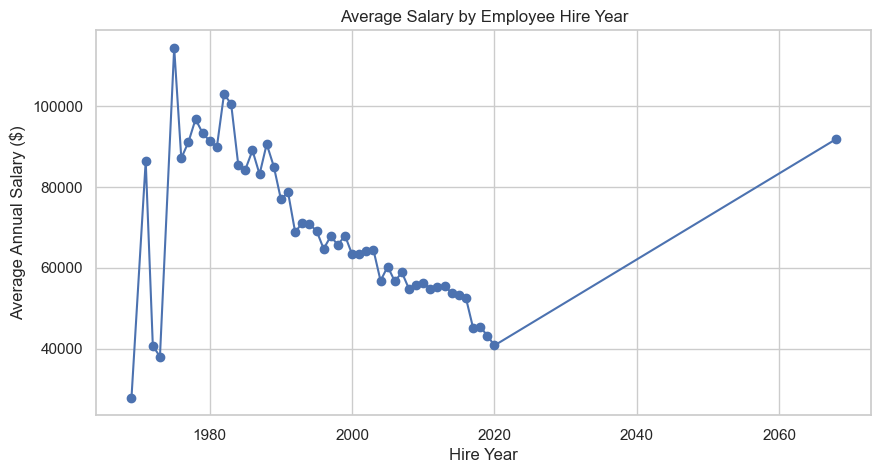

In [64]:
# Changes in salary and headcount over time

if "employ_date" in df_clean.columns:
    time_data = df_clean.dropna(subset=["employ_date"]).copy()
    time_data["employment_year"] = (
        time_data["employ_date"].dt.year
    )

    yearly_summary = (
        time_data.groupby("employment_year")
        .agg(
            average_annual_salary=("annual", "mean"),
            median_annual_salary=("annual", "median"),
            employee_records=("annual", "count")
        )
        .round(2)
    )

    display(yearly_summary.tail(15))

    yearly_summary["average_annual_salary"].plot(
        figsize=(10, 5),
        marker="o",
        title="Average Salary by Employee Hire Year"
    )
    import matplotlib.pyplot as plt
    plt.ylabel("Average Annual Salary ($)")
    plt.xlabel("Hire Year")
    plt.grid(True)
    plt.show()
else:
    print("Employment date is unavailable for time analysis.")



## Challenges and Solutions

1. **Missing values:** Some columns contained substantial missing data.
   Unusable metadata columns were removed, and imputers were used
   inside the machine learning preprocessing pipeline.

2. **Categorical variables:** Agency, job title, gender, ethnicity,
   and employment status contain categorical information.
   One-hot encoding was used to prepare these features.

3. **Salary outliers:** Extreme salary values can affect regression
   performance. The IQR method was used to identify potential outliers.

4. **Data leakage:** Monthly salary and hourly rate were excluded
   from the selected predictors because they could reveal information
   about annual salary.

5. **Model selection:** Multiple regression models were evaluated
   using MAE, RMSE, R², and training time.

6. **Limitations:** The available data may not contain reliable
   manager classifications, historical compensation snapshots, or
   total compensation components. These analyses require additional
   data.



## Recommendations

- Review salary distributions across agencies and job classifications.
- Investigate unusually high or low salaries in their job and employment
  context before drawing conclusions.
- Examine salary differences across demographic groups using
  appropriate controls for role, experience, hours, and other relevant
  factors.
- Collect reliable historical salary, benefits, total compensation,
  and management-level information for stronger workforce analysis.
- Use the selected machine learning model as a decision-support tool,
  not as the sole basis for salary decisions.
- Retrain and evaluate the model when new, representative payroll data
  becomes available.



## Conclusion

This project explored Texas public-sector payroll data and developed
a machine learning pipeline to predict annual salary using selected
employment and job-related features.

The workflow included data cleaning, exploratory data analysis,
salary outlier detection, feature selection, preprocessing,
train-test splitting, model comparison, evaluation, and model saving.

Several regression algorithms were compared using Mean Absolute
Error (MAE), Root Mean Squared Error (RMSE), and R². The best
performing model was selected based on the evaluation results and
saved as `texas_salary_model.pkl`.

The analysis provides a foundation for examining salary distributions,
agency-level differences, and workforce patterns. Results should be
interpreted with awareness of data limitations, potential bias,
and the difference between statistical associations and causal effects.

Future improvements could include additional compensation fields,
reliable historical payroll records, better management-level data,
hyperparameter tuning, and evaluation on newer payroll records.
